In [32]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("styles/plots.mplstyle")


In [33]:
from tkinter.ttk import Separator

riscaldamento = np.genfromtxt(
    f"dataset/dataset_eltek/prova_phon/2026-07-02_Prova Housing-4 termocoppie_Phon_Riscaldamento.csv", 
    delimiter=";",
    skip_header=1,
    usecols=(0,1,2,3,4)
)
raffreddamento = np.genfromtxt(
    f"dataset/dataset_eltek/prova_phon/2026-07-02_Prova Housing-4 termocoppie_Phon_Raffreddamento.csv", 
    delimiter=";",
    skip_header=1,
    usecols=(0,1,2,3,4)
)

In [34]:
# Temperature shiftate rispetto all'ambiente

dati_usati = riscaldamento

low_idx = 60000
high_idx= 90000

T_amb_mean = np.mean(dati_usati[low_idx:high_idx,4])

Theta_0 = dati_usati[low_idx:high_idx,1] - T_amb_mean # misura sensore
Theta_1 = dati_usati[low_idx:high_idx,2] - T_amb_mean 
Theta_2 = dati_usati[low_idx:high_idx,3] - T_amb_mean # temperatura reale
Theta_3 = dati_usati[low_idx:high_idx,4] - T_amb_mean # temperatura ambiente

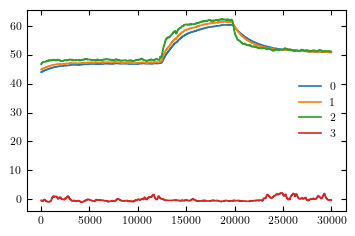

In [35]:
plt.plot(Theta_0, label="0")
plt.plot(Theta_1, label="1")
plt.plot(Theta_2, label="2")
plt.plot(Theta_3, label="3")

plt.legend()

In [36]:
# Parametri simulazione
L = 0.003 # (metri)
dt = riscaldamento[-1,0] - riscaldamento[-2,0]
nt = np.size(Theta_0)
Tf = dt*nt

# Proprietà Al₂O₃
rho_Al2O3 = 3960        # kg/m³
cp_Al2O3 = 880          # J/(kg·K)
kappa_Al2O3 = 25        # W/(m·K) per Al₂O₃ tecnica
D = kappa_Al2O3 / (rho_Al2O3 * cp_Al2O3)
print(D)
# D ≈ 7.1e-6 m²/s

wanted_r = 0.5
h = 12

from src.Heat1DCrankNicolson import Heat1DCrankNicolson

# Inizializza solver
solver = Heat1DCrankNicolson(L,Tf,nt,D,h,wanted_r=wanted_r)
solver.info()

_, n_eff = solver.diffusion_time()

from src.TikhonovHandler import TikhonovHandler, reconstruction_error_plot
th = TikhonovHandler(solver)

7.1740128558310376e-06

-----------------------------Solver info------------------------------

Diffusion time:                                               1.25e+00
dx:                                                           4.29e-04
dt:                                                           1.00e-02
nt:                                                              30000
nx:                                                                  8
r:                                                            3.91e-01
h:                                                            1.20e+01


(30000,)
(30000,)


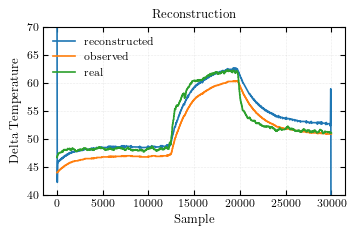

In [37]:
g_target = Theta_0

f_reconstructed = th.regularize(g_target, lambda_reg=5, regularization_type_="closed")

print(np.shape(g_target))
print(np.shape(f_reconstructed))

plt.plot(f_reconstructed, label="reconstructed")
plt.plot(g_target, label="observed")
plt.plot(Theta_2, label="real")
plt.xlabel("Sample")
plt.ylabel("Delta Temperature")
plt.title("Reconstruction")
plt.grid()
plt.ylim([40,70])
plt.legend()

plt.savefig(f"assets/tikhonov_learned/eltek_images/img2.pdf", dpi=150, bbox_inches='tight')